Countries with missing Population or GDP:
['Afghanistan', 'American Samoa', 'Anguilla', 'Aruba', 'Bahamas', 'Bermuda', 'Bouvet Island', 'Cayman Islands', 'Cook Islands (the)', 'Cuba', 'Curacao', 'Eritrea', 'French Guiana', 'French Polynesia', 'Guadeloupe', 'Guam', 'Lebanon', 'Liechtenstein', 'Martinique', 'Mayotte', 'Montserrat', 'Nauru', 'Netherlands Antilles', 'New Caledonia', 'Niue', 'North Korea', 'Northern Mariana Islands', 'Other Africa', 'Other Latin America', 'Other Oceania', 'Pitcairn Islands', 'Reunion', 'Saint Barthelemy', 'Saint Helena and Ascension and Tristan da Cunha', 'Saint Martin (French part)', 'South Sudan', 'Syria', 'Taiwan (China)', 'Turks and Caicos Islands', 'United Arab Emirates', 'United States Minor Outlying Islands', 'Virgin Islands (British)', 'Virgin Islands (U.S.)', 'Wallis and Futuna', 'Yemen']

Years included: [2022, 2023, 2024, 2025]

Country observations: 197
Region observations: 7


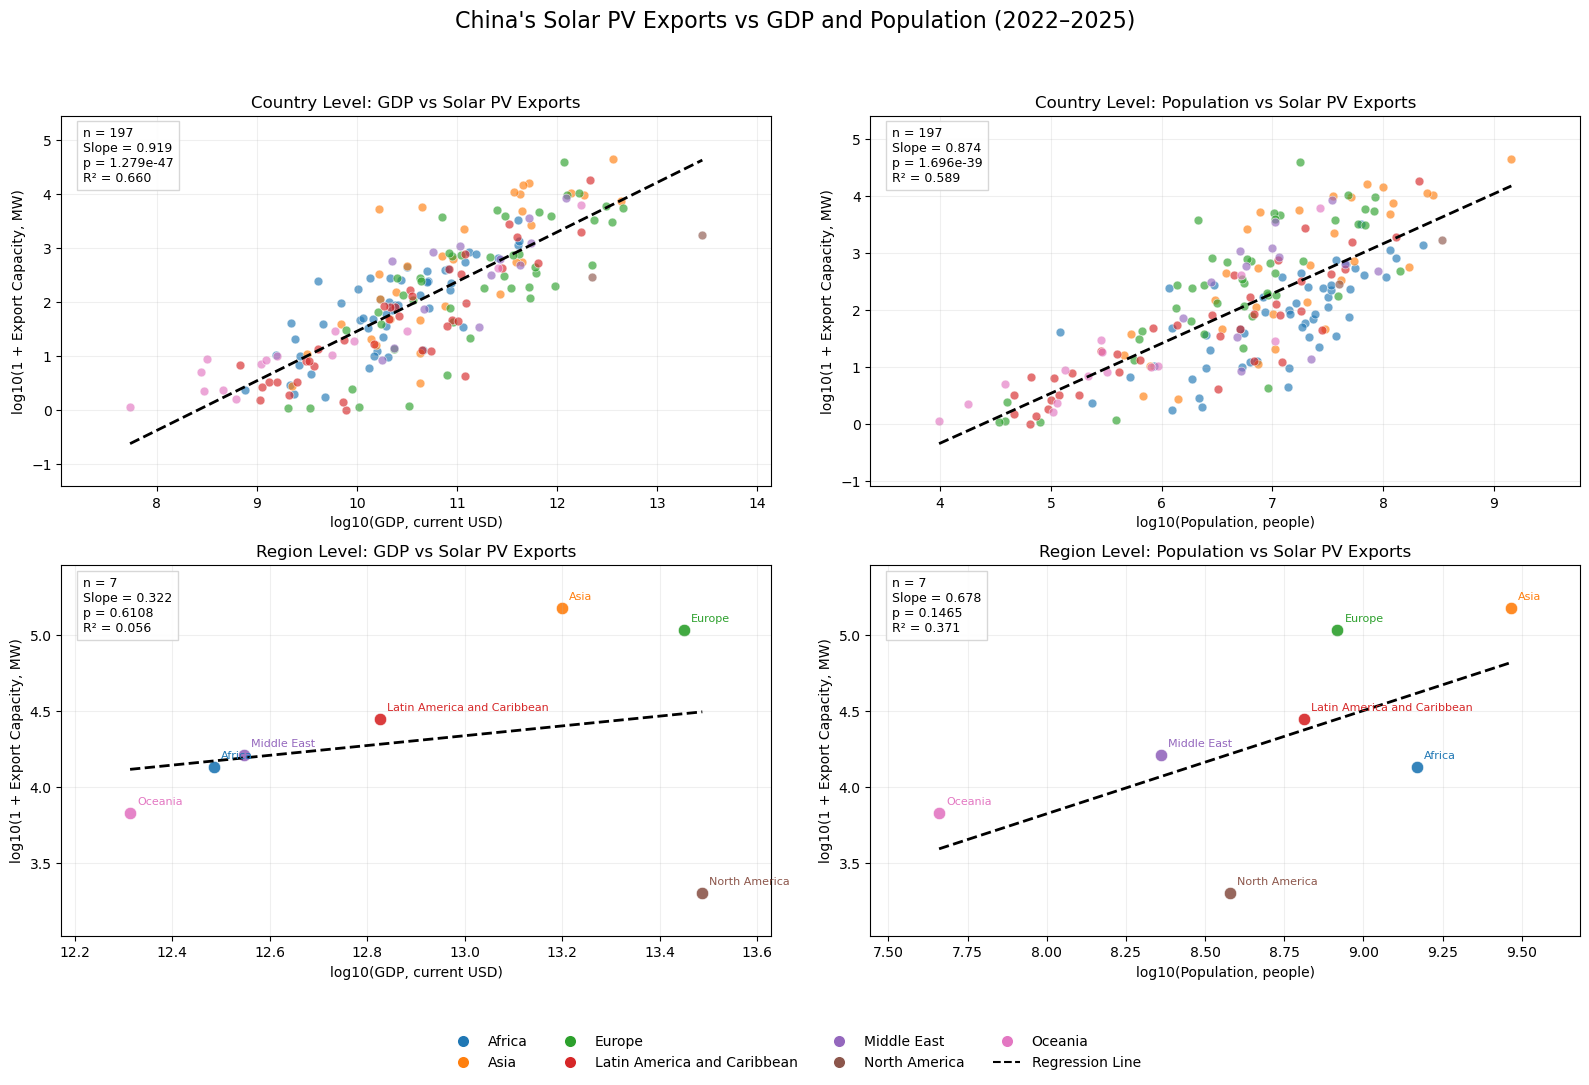


===== Regression Results =====
  Level   Variable  Coefficient  P-value  R-squared
Country        GDP       0.9185   0.0000     0.6605
Country Population       0.8741   0.0000     0.5889
 Region        GDP       0.3218   0.6108     0.0556
 Region Population       0.6776   0.1465     0.3711


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.lines import Line2D

solar_path = "/Users/zhouxuan/Desktop/Duke/ZhengWangZhou/ZhengWangZhouLi/data/solarexport_data.csv"
pop_path = "/Users/zhouxuan/Desktop/global_Pop.csv"
gdp_path = "/Users/zhouxuan/Desktop/global_GDP.csv"

solar = pd.read_csv(solar_path)
pop = pd.read_csv(pop_path, skiprows=4)
gdp = pd.read_csv(gdp_path, skiprows=4)

years = [str(y) for y in range(2022, 2026)]

def to_long(data, name):
    result = data.melt(
        id_vars=["Country Name", "Country Code"],
        value_vars=years,
        var_name="Year",
        value_name=name
    )
    result["Year"] = result["Year"].astype(int)
    result[name] = pd.to_numeric(
        result[name], errors="coerce"
    )
    return result

pop_long = to_long(pop, "Population")
gdp_long = to_long(gdp, "GDP")

economic = pop_long.merge(
    gdp_long[["Country Code", "Year", "GDP"]],
    on=["Country Code", "Year"],
    validate="one_to_one"
)

solar["Date"] = pd.to_datetime(
    solar["Date"], errors="coerce"
)
solar["Year"] = solar["Date"].dt.year

solar["Capacity (MW)"] = pd.to_numeric(
    solar["Capacity (MW)"], errors="coerce"
)

solar_clean = solar[
    (solar["Area type"] == "Country or economy") &
    (solar["Commodity type"].isin(
        ["Panels", "Cells", "Wafers"]
    )) &
    (solar["Year"].between(2022, 2025)) &
    (solar["Region"].notna())
].copy()

annual = (
    solar_clean.groupby(
        ["Area", "Region", "Year"],
        as_index=False
    )["Capacity (MW)"]
    .sum(min_count=1)
    .rename(columns={"Capacity (MW)": "Export_MW"})
)


name_map = {
    "Bahamas": "Bahamas, The",
    "Bosnia Herzegovina": "Bosnia and Herzegovina",
    "Congo": "Congo, Rep.",
    "Congo (DRC)": "Congo, Dem. Rep.",
    "Egypt": "Egypt, Arab Rep.",
    "Gambia": "Gambia, The",
    "Hong Kong (SAR of China)": "Hong Kong SAR, China",
    "Iran": "Iran, Islamic Rep.",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Macao (SAR of China)": "Macao SAR, China",
    "Micronesia": "Micronesia, Fed. Sts.",
    "North Korea": "Korea, Dem. People's Rep.",
    "South Korea": "Korea, Rep.",
    "Palestine (State of)": "West Bank and Gaza",
    "Puerto Rico": "Puerto Rico (US)",
    "Russia": "Russian Federation",
    "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia",
    "Saint Martin (French part)": "St. Martin (French part)",
    "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Slovakia": "Slovak Republic",
    "Somalia": "Somalia, Fed. Rep.",
    "Syria": "Syrian Arab Republic",
    "Tanzania (the United Republic of)": "Tanzania",
    "The Philippines": "Philippines",
    "Türkiye": "Turkiye",
    "Venezuela": "Venezuela, RB",
    "Yemen": "Yemen, Rep."
}

annual["Country Name"] = annual["Area"].replace(name_map)

merged = annual.merge(
    economic[
        ["Country Name", "Year", "Population", "GDP"]
    ],
    on=["Country Name", "Year"],
    how="left",
    validate="many_to_one"
)

print("Countries with missing Population or GDP:")
print(sorted(merged.loc[
    merged[["Population", "GDP"]].isna().any(axis=1),
    "Area"
].unique()))

matched = merged.dropna(
    subset=["Export_MW", "Population", "GDP"]
).copy()

matched = matched[
    (matched["Export_MW"] >= 0) &
    (matched["Population"] > 0) &
    (matched["GDP"] > 0)
].copy()

print("\nYears included:", sorted(matched["Year"].unique()))


country = (
    matched.groupby(
        ["Area", "Region"],
        as_index=False
    )
    .agg(
        GDP=("GDP", "mean"),
        Population=("Population", "mean"),
        Export_MW=("Export_MW", "mean")
    )
)


region_year = (
    matched.groupby(
        ["Region", "Year"],
        as_index=False
    )
    .agg(
        GDP=("GDP", "sum"),
        Population=("Population", "sum"),
        Export_MW=("Export_MW", "sum")
    )
)

region = (
    region_year.groupby(
        "Region", as_index=False
    )[["GDP", "Population", "Export_MW"]]
    .mean()
)

print("\nCountry observations:", len(country))
print("Region observations:", len(region))


region_order = [
    "Africa",
    "Asia",
    "Europe",
    "Latin America and Caribbean",
    "Middle East",
    "North America",
    "Oceania"
]

palette = plt.get_cmap("tab10").colors

region_colors = {
    r: palette[i]
    for i, r in enumerate(region_order)
}

def regression_plot(ax, data, variable, title, region_labels=False):

    # Log transformation
    x = np.log10(data[variable].astype(float))
    y = np.log10(1 + data["Export_MW"].astype(float))

    # Plot each region using its assigned color
    for r in region_order:
        subset = data["Region"] == r

        if subset.any():
            ax.scatter(
                x[subset],
                y[subset],
                color=region_colors[r],
                s=80 if region_labels else 40,
                alpha=0.9 if region_labels else 0.65,
                edgecolors="white",
                linewidths=0.5
            )

    # Simple Linear Regression
    X = sm.add_constant(
        pd.DataFrame({"x": x}),
        has_constant="add"
    )

    model = sm.OLS(y, X).fit()

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 100)

    y_line = (
        model.params["const"] +
        model.params["x"] * x_line
    )

    ax.plot(
        x_line,
        y_line,
        color="black",
        linestyle="--",
        linewidth=2
    )

    # Label regions in region-level plots
    if region_labels:
        for i, row in data.iterrows():
            ax.annotate(
                row["Region"],
                (x.loc[i], y.loc[i]),
                xytext=(5, 6),
                textcoords="offset points",
                fontsize=8,
                color=region_colors[row["Region"]]
            )

    # Titles and axis labels
    ax.set_title(title)

    if variable == "GDP":
        ax.set_xlabel("log10(GDP, current USD)")
    else:
        ax.set_xlabel("log10(Population, people)")

    ax.set_ylabel("log10(1 + Export Capacity, MW)")

    # Display regression results
    ax.text(
        0.03, 0.97,
        f"n = {len(data)}\n"
        f"Slope = {model.params['x']:.3f}\n"
        f"p = {model.pvalues['x']:.4g}\n"
        f"R² = {model.rsquared:.3f}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(
            facecolor="white",
            edgecolor="lightgray",
            alpha=0.9
        )
    )

    ax.grid(alpha=0.2)
    ax.margins(x=0.12, y=0.15)

    return model

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Country Level
model_country_gdp = regression_plot(
    axes[0, 0],
    country,
    "GDP",
    "Country Level: GDP vs Solar PV Exports"
)

model_country_pop = regression_plot(
    axes[0, 1],
    country,
    "Population",
    "Country Level: Population vs Solar PV Exports"
)

# Region Level
model_region_gdp = regression_plot(
    axes[1, 0],
    region,
    "GDP",
    "Region Level: GDP vs Solar PV Exports",
    region_labels=True
)

model_region_pop = regression_plot(
    axes[1, 1],
    region,
    "Population",
    "Region Level: Population vs Solar PV Exports",
    region_labels=True
)


legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=region_colors[r],
        markeredgecolor="white",
        markersize=9,
        label=r
    )
    for r in region_order
]

legend_items.append(
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        label="Regression Line"
    )
)

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.005)
)

fig.suptitle(
    "China's Solar PV Exports vs GDP and Population (2022–2025)",
    fontsize=16
)

plt.tight_layout(rect=[0, 0.085, 1, 0.95])

# Save figure
plt.savefig(
    "solar_four_regressions_2022_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

models = [
    ("Country", "GDP", model_country_gdp),
    ("Country", "Population", model_country_pop),
    ("Region", "GDP", model_region_gdp),
    ("Region", "Population", model_region_pop)
]

results = []

for level, variable, model in models:
    results.append({
        "Level": level,
        "Variable": variable,
        "Coefficient": model.params["x"],
        "P-value": model.pvalues["x"],
        "R-squared": model.rsquared
    })

results_df = pd.DataFrame(results)

print("\n===== Regression Results =====")
print(results_df.round(4).to_string(index=False))

# Save results
results_df.to_csv(
    "solar_regression_results_2022_2025.csv",
    index=False
)
